In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df=pd.read_csv(r"H:\datasets\archive\ecommerce_retail_visualization_dataset.csv")

In [5]:
df.head()

,Order_ID,Order_Date,Region,State,Product_Category,Product,Customer_Segment,Sales,Quantity,Discount,Profit,Shipping_Cost,Rating,Delivery_Days
0,ORD-00193,2025-11-28,South,Telangana,Furniture,Filing Cabinet,Consumer,4717.12,1,0.052,981.80,107.11,2.8,7
1,ORD-00719,2025-05-09,South,Karnataka,Office Supplies,Desk Organizer,Corporate,8506.94,7,0.104,1148.29,309.69,3.5,5
2,ORD-00169,2025-07-02,South,Tamil Nadu,Electronics,Wireless Headphones,Corporate,20485.91,5,0.070,3115.63,321.38,3.5,4
3,ORD-00523,2025-04-15,West,Maharashtra,Furniture,Bookshelf,Home Office,25500.16,7,0.105,3721.38,537.72,4.2,2
4,ORD-00537,2025-09-06,Central,Uttar Pradesh,Furniture,Bookshelf,Corporate,14754.57,4,0.113,1906.72,261.48,4.0,4


In [9]:
df.dtypes

Order_ID                    object
Order_Date          datetime64[ns]
Region                      object
State                       object
Product_Category            object
Product                     object
Customer_Segment            object
Sales                      float64
Quantity                     int64
Discount                   float64
Profit                     float64
Shipping_Cost              float64
Rating                     float64
Delivery_Days                int64
dtype: object

In [8]:
df["Order_Date"]=pd.to_datetime(df["Order_Date"])

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 805 entries, 0 to 804
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Order_ID          805 non-null    object        
 1   Order_Date        805 non-null    datetime64[ns]
 2   Region            805 non-null    object        
 3   State             801 non-null    object        
 4   Product_Category  805 non-null    object        
 5   Product           802 non-null    object        
 6   Customer_Segment  802 non-null    object        
 7   Sales             805 non-null    float64       
 8   Quantity          805 non-null    int64         
 9   Discount          803 non-null    float64       
 10  Profit            805 non-null    float64       
 11  Shipping_Cost     805 non-null    float64       
 12  Rating            802 non-null    float64       
 13  Delivery_Days     805 non-null    int64         
dtypes: datetime64[ns](1), floa

In [11]:
df.describe()

,Order_Date,Sales,Quantity,Discount,Profit,Shipping_Cost,Rating,Delivery_Days
count,805,805.000000,805.000000,803.000000,805.000000,805.000000,802.000000,805.000000
mean,2025-10-05 02:17:44.347826432,11443.565416,4.047205,0.101345,1758.842137,277.581280,4.106110,4.655901
min,2025-01-03 00:00:00,726.370000,1.000000,0.020000,-205.750000,74.020000,2.300000,1.000000
25%,2025-05-24 00:00:00,4724.910000,2.000000,0.059000,630.620000,159.590000,3.800000,4.000000
50%,2025-10-04 00:00:00,9114.030000,4.000000,0.094000,1286.470000,246.880000,4.100000,5.000000
75%,2026-02-22 00:00:00,15306.460000,5.000000,0.134000,2311.690000,356.950000,4.500000,6.000000
max,2026-06-29 00:00:00,53594.030000,10.000000,0.335000,12129.640000,970.320000,5.000000,9.000000
std,NaN,8952.175053,2.313223,0.054505,1616.641001,154.006855,0.506709,1.376637


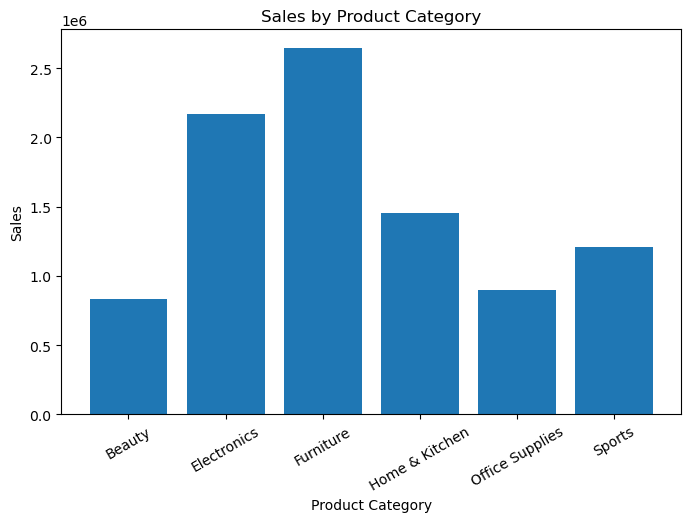

In [21]:
category_sales = df.groupby("Product_Category")["Sales"].sum()

plt.figure(figsize=(8,5))
plt.bar(category_sales.index, category_sales.values)

plt.title("Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Sales")

plt.xticks(rotation=30)
plt.show()

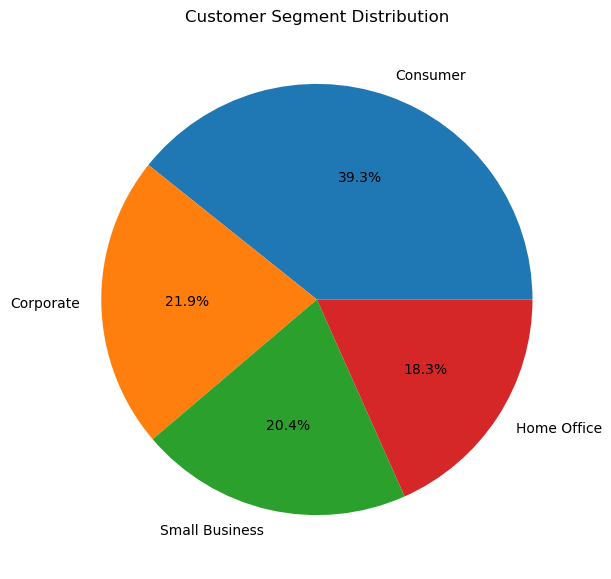

In [22]:
segment = df["Customer_Segment"].value_counts()

plt.figure(figsize=(7,7))
plt.pie(segment.values, labels=segment.index, autopct="%1.1f%%")

plt.title("Customer Segment Distribution")
plt.show()

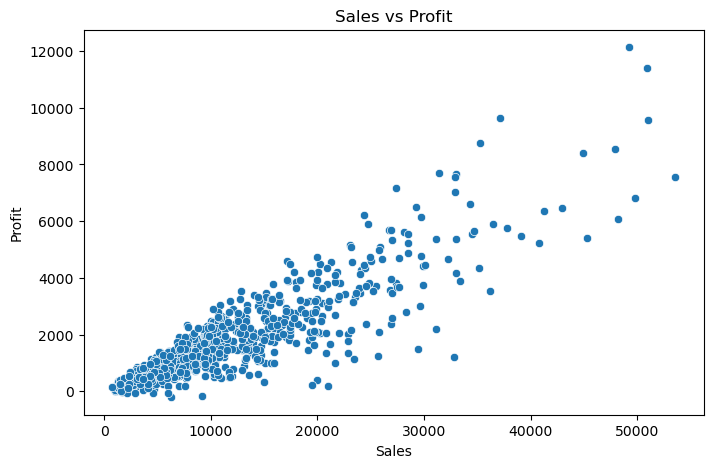

In [23]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="Sales",
    y="Profit"
)

plt.title("Sales vs Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")

plt.show()

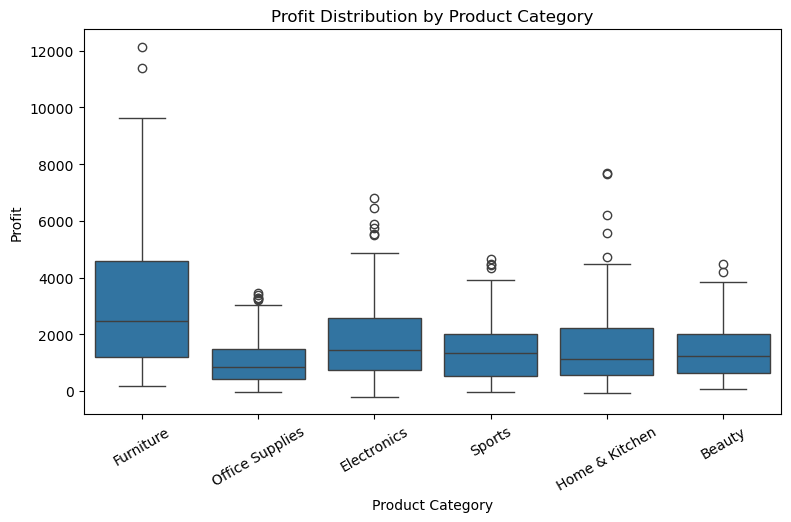

In [24]:
plt.figure(figsize=(9,5))

sns.boxplot(
    data=df,
    x="Product_Category",
    y="Profit"
)

plt.title("Profit Distribution by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Profit")

plt.xticks(rotation=30)
plt.show()

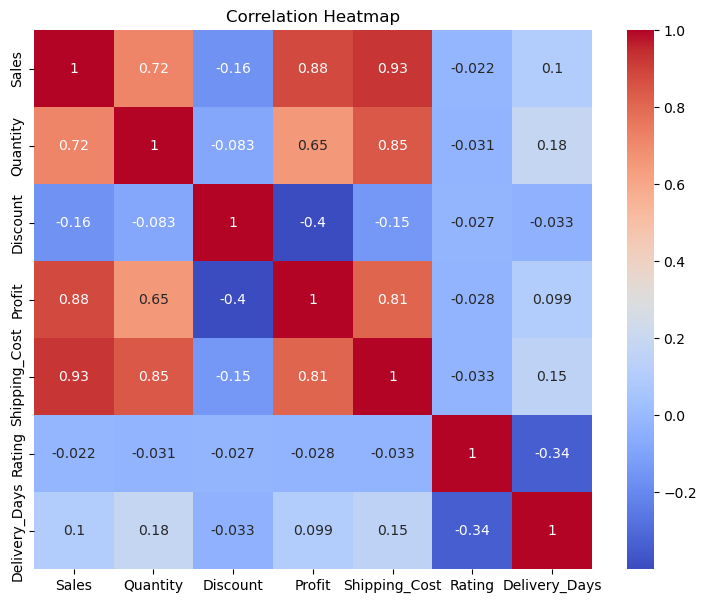

In [25]:
columns = [
    "Sales",
    "Quantity",
    "Discount",
    "Profit",
    "Shipping_Cost",
    "Rating",
    "Delivery_Days"
]

correlation = df[columns].corr()

plt.figure(figsize=(9,7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()